If there is a problem with selecting kernel of ipynb in vscode, try reinstalling some vscode extensions: Python, Pylance, Jupyter. Please follow this [post](https://github.com/microsoft/vscode-jupyter/issues/10043#issuecomment-1429290022)

In [1]:
import collections
import json
import os
import shutil

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight

In [2]:
INPUT_PATH = '/data/hqvo3/Datasets/vlm/ml-scripts/datasets/glom_refine_splits/split{}'
N_SPLITS = 3

In [3]:
cnt_dict = {}
list_of_categories = None

for split_id in range(N_SPLITS):
  SPLIT_PATH = INPUT_PATH.format(split_id)
  cnt_dict[split_id] = {}
  for subset_id in ['train', 'val', 'test']:
    cnt_dict[split_id][subset_id] = {}
    SUBSET_PATH = os.path.join(SPLIT_PATH, subset_id)
    print(SUBSET_PATH)
    categories = os.listdir(SUBSET_PATH)
    categories.sort()
    if list_of_categories is None:
      list_of_categories = categories.copy()
    print(categories)
    for category in categories:
      CATEGORY_PATH = os.path.join(SUBSET_PATH, category)
      cur_filenames = os.listdir(CATEGORY_PATH)
      cnt_dict[split_id][subset_id][category] = len(cur_filenames)
      print(f'Split {split_id}, subset {subset_id}, class {category}, #samples {len(cur_filenames)}')

/data/hqvo3/Datasets/vlm/ml-scripts/datasets/glom_refine_splits/split0/train
['endocapillary_hypercellularity', 'exudative_glomerulus', 'fibrinoid_necrosis_glomerulus', 'fibrocellular_crescent', 'fibrous_crescent', 'glomerul_lipoprotein_thrombus', 'glomerular_adhesion', 'glomerular_basement_membrane_duplication_splitting', 'glomerular_basement_membrane_thickening', 'glomerular_collapse', 'glomerular_congestion', 'glomerular_foam_cell', 'glomerular_hyaline_pseudothrombus', 'glomerular_hyalinosis', 'glomerular_obsolesce', 'glomerular_segmental_sclerosis', 'glomerular_thrombus', 'glomerulomegaly', 'glomerulonephritis_hyaline_thrombus', 'glomerulus_endotheliosis', 'hyalin_drop_diabetic_glomerulus', 'immature_glomerulus', 'ischemic_glomerular_collapse', 'karyorrhexis_glomerulonephritis', 'membranous_nephropathy_holes', 'membranous_nephropathy_spikes', 'mesangial_hypercellularity', 'mesangial_matrix_expansion', 'mesangiolysis', 'nodular_sclerosis_glomerulus', 'parietal_cell_glomerulus', 'per

In [4]:
list_of_categories

['endocapillary_hypercellularity',
 'exudative_glomerulus',
 'fibrinoid_necrosis_glomerulus',
 'fibrocellular_crescent',
 'fibrous_crescent',
 'glomerul_lipoprotein_thrombus',
 'glomerular_adhesion',
 'glomerular_basement_membrane_duplication_splitting',
 'glomerular_basement_membrane_thickening',
 'glomerular_collapse',
 'glomerular_congestion',
 'glomerular_foam_cell',
 'glomerular_hyaline_pseudothrombus',
 'glomerular_hyalinosis',
 'glomerular_obsolesce',
 'glomerular_segmental_sclerosis',
 'glomerular_thrombus',
 'glomerulomegaly',
 'glomerulonephritis_hyaline_thrombus',
 'glomerulus_endotheliosis',
 'hyalin_drop_diabetic_glomerulus',
 'immature_glomerulus',
 'ischemic_glomerular_collapse',
 'karyorrhexis_glomerulonephritis',
 'membranous_nephropathy_holes',
 'membranous_nephropathy_spikes',
 'mesangial_hypercellularity',
 'mesangial_matrix_expansion',
 'mesangiolysis',
 'nodular_sclerosis_glomerulus',
 'parietal_cell_glomerulus',
 'periglomerular_fibrosis',
 'podocyte',
 'podocyte

In [5]:
# OrderedDict is dictionary with sorted keys so that when using loop to print, it will print in the sorted alphabetical order of keys
train_ordered_dict_0 = collections.OrderedDict(sorted(cnt_dict[0]['train'].items()))
val_ordered_dict_0 = collections.OrderedDict(sorted(cnt_dict[0]['val'].items()))
test_ordered_dict_0 = collections.OrderedDict(sorted(cnt_dict[0]['test'].items()))

train_ordered_dict_1 = collections.OrderedDict(sorted(cnt_dict[1]['train'].items()))
val_ordered_dict_1 = collections.OrderedDict(sorted(cnt_dict[1]['val'].items()))
test_ordered_dict_1 = collections.OrderedDict(sorted(cnt_dict[1]['test'].items()))

train_ordered_dict_2 = collections.OrderedDict(sorted(cnt_dict[2]['train'].items()))
val_ordered_dict_2 = collections.OrderedDict(sorted(cnt_dict[2]['val'].items()))
test_ordered_dict_2 = collections.OrderedDict(sorted(cnt_dict[2]['test'].items()))

In [6]:
len(test_ordered_dict_0.keys())

42

In [7]:
print(test_ordered_dict_0.keys())
print(test_ordered_dict_0.items())

odict_keys(['endocapillary_hypercellularity', 'exudative_glomerulus', 'fibrinoid_necrosis_glomerulus', 'fibrocellular_crescent', 'fibrous_crescent', 'glomerul_lipoprotein_thrombus', 'glomerular_adhesion', 'glomerular_basement_membrane_duplication_splitting', 'glomerular_basement_membrane_thickening', 'glomerular_collapse', 'glomerular_congestion', 'glomerular_foam_cell', 'glomerular_hyaline_pseudothrombus', 'glomerular_hyalinosis', 'glomerular_obsolesce', 'glomerular_segmental_sclerosis', 'glomerular_thrombus', 'glomerulomegaly', 'glomerulonephritis_hyaline_thrombus', 'glomerulus_endotheliosis', 'hyalin_drop_diabetic_glomerulus', 'immature_glomerulus', 'ischemic_glomerular_collapse', 'karyorrhexis_glomerulonephritis', 'membranous_nephropathy_holes', 'membranous_nephropathy_spikes', 'mesangial_hypercellularity', 'mesangial_matrix_expansion', 'mesangiolysis', 'nodular_sclerosis_glomerulus', 'parietal_cell_glomerulus', 'periglomerular_fibrosis', 'podocyte', 'podocyte_hyperplasia', 'podocy

In [8]:
for key, item in test_ordered_dict_0.items():
  print(item, end=' ')
print()
for key, item in test_ordered_dict_1.items():
  print(item, end=' ')
print()
for key, item in test_ordered_dict_2.items():
  print(item, end=' ')

34 8 26 36 11 6 53 4 27 76 23 15 9 38 5 77 32 17 12 10 3 40 16 5 6 16 60 111 26 33 20 15 6 25 16 2 8 24 5 20 3 11 
34 8 26 36 11 6 53 4 27 76 23 15 9 38 5 77 32 17 12 10 3 40 16 5 6 16 60 111 26 33 20 15 6 24 16 2 8 25 5 20 3 11 
34 8 26 36 11 6 53 4 27 76 23 15 9 38 5 77 32 17 12 10 3 40 16 5 6 16 60 111 26 33 20 15 6 24 16 2 8 25 5 20 3 11 

In [9]:
# ===== TRAIN =====
print('===== TRAIN =====')
recreated_labels_list_0 = []
recreated_labels_list_1 = []
recreated_labels_list_2 = []

for cls_idx, (key, item) in enumerate(train_ordered_dict_0.items()):
  recreated_labels_list_0.extend([cls_idx]*item)
for cls_idx, (key, item) in enumerate(train_ordered_dict_1.items()):
  recreated_labels_list_1.extend([cls_idx]*item)
for cls_idx, (key, item) in enumerate(train_ordered_dict_2.items()):
  recreated_labels_list_2.extend([cls_idx]*item)

print(recreated_labels_list_0)
print(len(recreated_labels_list_0))
print(recreated_labels_list_1)
print(len(recreated_labels_list_1))
print(recreated_labels_list_2)
print(len(recreated_labels_list_2))

# ===== VAL =====
print('===== VAL =====')
recreated_labels_list_0 = []
recreated_labels_list_1 = []
recreated_labels_list_2 = []

for cls_idx, (key, item) in enumerate(val_ordered_dict_0.items()):
  recreated_labels_list_0.extend([cls_idx]*item)
for cls_idx, (key, item) in enumerate(val_ordered_dict_1.items()):
  recreated_labels_list_1.extend([cls_idx]*item)
for cls_idx, (key, item) in enumerate(val_ordered_dict_2.items()):
  recreated_labels_list_2.extend([cls_idx]*item)

print(recreated_labels_list_0)
print(len(recreated_labels_list_0))
print(recreated_labels_list_1)
print(len(recreated_labels_list_1))
print(recreated_labels_list_2)
print(len(recreated_labels_list_2))

# ===== TEST =====
print('===== TEST =====')
recreated_labels_list_0 = []
recreated_labels_list_1 = []
recreated_labels_list_2 = []

for cls_idx, (key, item) in enumerate(test_ordered_dict_0.items()):
  recreated_labels_list_0.extend([cls_idx]*item)
for cls_idx, (key, item) in enumerate(test_ordered_dict_1.items()):
  recreated_labels_list_1.extend([cls_idx]*item)
for cls_idx, (key, item) in enumerate(test_ordered_dict_2.items()):
  recreated_labels_list_2.extend([cls_idx]*item)

print(recreated_labels_list_0)
print(len(recreated_labels_list_0))
print(recreated_labels_list_1)
print(len(recreated_labels_list_1))
print(recreated_labels_list_2)
print(len(recreated_labels_list_2))

===== TRAIN =====
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 

In [10]:
# === compute class weights ===
class_weights_0 = compute_class_weight(class_weight="balanced", classes=np.unique(recreated_labels_list_0), y=recreated_labels_list_0)
class_weights_1 = compute_class_weight(class_weight="balanced", classes=np.unique(recreated_labels_list_1), y=recreated_labels_list_1)
class_weights_2 = compute_class_weight(class_weight="balanced", classes=np.unique(recreated_labels_list_2), y=recreated_labels_list_2)

print(*class_weights_0, sep=", ")
# print(*class_weights_1, sep=", ")
# print(*class_weights_2, sep=", ")

0.6932773109243697, 2.9464285714285716, 0.9065934065934066, 0.6547619047619048, 2.142857142857143, 3.9285714285714284, 0.444743935309973, 5.892857142857143, 0.873015873015873, 0.3101503759398496, 1.0248447204968945, 1.5714285714285714, 2.619047619047619, 0.6203007518796992, 4.714285714285714, 0.30612244897959184, 0.7366071428571429, 1.3865546218487395, 1.9642857142857142, 2.357142857142857, 7.857142857142857, 0.5892857142857143, 1.4732142857142858, 4.714285714285714, 3.9285714285714284, 1.4732142857142858, 0.39285714285714285, 0.21235521235521235, 0.9065934065934066, 0.7142857142857143, 1.1785714285714286, 1.5714285714285714, 3.9285714285714284, 0.9428571428571428, 1.4732142857142858, 11.785714285714286, 2.9464285714285716, 0.9821428571428571, 4.714285714285714, 1.1785714285714286, 7.857142857142857, 2.142857142857143


In [11]:
train_ordered_dict_0
val_ordered_dict_0
test_ordered_dict_0

train_ordered_dict_1
val_ordered_dict_1
test_ordered_dict_1

train_ordered_dict_2
val_ordered_dict_2
test_ordered_dict_2

OrderedDict([('endocapillary_hypercellularity', 34),
             ('exudative_glomerulus', 8),
             ('fibrinoid_necrosis_glomerulus', 26),
             ('fibrocellular_crescent', 36),
             ('fibrous_crescent', 11),
             ('glomerul_lipoprotein_thrombus', 6),
             ('glomerular_adhesion', 53),
             ('glomerular_basement_membrane_duplication_splitting', 4),
             ('glomerular_basement_membrane_thickening', 27),
             ('glomerular_collapse', 76),
             ('glomerular_congestion', 23),
             ('glomerular_foam_cell', 15),
             ('glomerular_hyaline_pseudothrombus', 9),
             ('glomerular_hyalinosis', 38),
             ('glomerular_obsolesce', 5),
             ('glomerular_segmental_sclerosis', 77),
             ('glomerular_thrombus', 32),
             ('glomerulomegaly', 17),
             ('glomerulonephritis_hyaline_thrombus', 12),
             ('glomerulus_endotheliosis', 10),
             ('hyalin_drop_diabeti

In [12]:
groupname2clsname = {"Glomerular Basement Membrane (GBM), Bowman's Capsule, Epithelial Cells": ['glomerular basement membrane duplication splitting',
                                                                                                'glomerular basement membrane thickening',
                                                                                                'hyalin drop diabetic glomerulus',
                                                                                                'membranous nephropathy holes',
                                                                                                'membranous nephropathy spikes',
                                                                                                'podocyte hyperplasia',
                                                                                                'podocyte hypertrophy',
                                                                                                'podocyte reabsorption droplet',
                                                                                                'spikes glomerular amyoidosis',
                                                                                                'visceral epithelial cell capping', \
                                                                                                'wire loop glomerulus',],\
                     "Mesangial and Endocapillary Lesions": ['endocapillary hypercellularity',
                                                             'exudative glomerulus',
                                                             'glomerul lipoprotein thrombus',
                                                             'glomerular congestion',
                                                             'glomerular hyaline pseudothrombus',
                                                             'glomerular thrombus',
                                                             'glomerulonephritis hyaline thrombus',
                                                             'glomerulus endotheliosis',
                                                             'mesangial hypercellularity',
                                                             'mesangial matrix expansion',
                                                             'mesangiolysis'], \
                     "Miscellaneous Lesions and Key Normal Structures": ['glomerulomegaly',
                                                                         'immature glomerulus',
                                                                         'parietal cell glomerulus',
                                                                         'podocyte',
                                                                         'visceral epithelial cell'], \
                     "Necrotizing and Crescentic Lesions": ['fibrinoid necrosis glomerulus',
                                                            'fibrocellular crescent', # subgroup: crescents
                                                            'fibrous crescent', # subgroup: crescents
                                                            'karyorrhexis glomerulonephritis',
                                                            'pseudocrescent'], \
                     "Tuft Sclerosis and Collapse": ['glomerular adhesion',
                                                     'glomerular collapse', # subgroup: capillary collapse
                                                     'glomerular foam cell',
                                                     'glomerular hyalinosis',
                                                     'glomerular obsolesce',
                                                     'glomerular segmental sclerosis', # subgroup: segmental sclerosis
                                                     'ischemic glomerular collapse', # subgroup: capillary collapse
                                                     'nodular sclerosis glomerulus', # subgroup: sclerosis
                                                     'periglomerular fibrosis',
                                                     'solidified glomerular sclerosis global'] # subgroup: sclerosis
}

In [13]:
clsname2groupname = {}
for grp_name, cls_names in groupname2clsname.items():
    for cls_name in cls_names:
        clsname2groupname[cls_name] = grp_name

In [14]:
parent_count_dict = {"Glomerular Basement Membrane (GBM), Bowman's Capsule, Epithelial Cells": 0, \
                     "Mesangial and Endocapillary Lesions": 0, \
                     "Miscellaneous Lesions and Key Normal Structures": 0, \
                     "Necrotizing and Crescentic Lesions": 0, \
                     "Tuft Sclerosis and Collapse": 0}

for cls_idx, (key, item) in enumerate(test_ordered_dict_0.items()):
    clsname = key.replace('_', ' ')
    grpname = clsname2groupname[clsname]
    parent_count_dict[grpname] += item

test_ordered_dict_parent_0 = collections.OrderedDict(sorted(parent_count_dict.items()))

In [15]:
recreated_labels_list_parent_0 = []

for cls_idx, (key, item) in enumerate(test_ordered_dict_parent_0.items()):
  print(key, item)
  recreated_labels_list_parent_0.extend([cls_idx]*item)

print(recreated_labels_list_parent_0)
print(len(recreated_labels_list_parent_0))

Glomerular Basement Membrane (GBM), Bowman's Capsule, Epithelial Cells 118
Mesangial and Endocapillary Lesions 331
Miscellaneous Lesions and Key Normal Structures 103
Necrotizing and Crescentic Lesions 86
Tuft Sclerosis and Collapse 352
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

In [16]:
# === compute class weights ===
class_weights_parent_0 = compute_class_weight(class_weight="balanced", classes=np.unique(recreated_labels_list_parent_0), y=recreated_labels_list_parent_0)

print(*class_weights_parent_0, sep=", ")

1.6779661016949152, 0.5981873111782477, 1.9223300970873787, 2.302325581395349, 0.5625


In [17]:
split0_table = []
split0_table.append(train_ordered_dict_0)
split0_table.append(val_ordered_dict_0)
split0_table.append(test_ordered_dict_0)
pd.DataFrame(split0_table, columns=list_of_categories, index=['train', 'val', 'test'])

,endocapillary_hypercellularity,exudative_glomerulus,fibrinoid_necrosis_glomerulus,fibrocellular_crescent,fibrous_crescent,glomerul_lipoprotein_thrombus,glomerular_adhesion,glomerular_basement_membrane_duplication_splitting,glomerular_basement_membrane_thickening,glomerular_collapse,...,podocyte,podocyte_hyperplasia,podocyte_hypertrophy,podocyte_reabsorption_droplet,pseudocrescent,solidified_glomerular_sclerosis_global,spikes_glomerular_amyoidosis,visceral_epithelial_cell,visceral_epithelial_cell_capping,wire_loop_glomerulus
train,103,25,76,106,34,19,157,14,79,229,...,19,73,48,7,25,73,14,61,8,32
val,34,8,25,35,12,6,52,4,27,76,...,7,24,16,2,9,25,4,21,2,11
test,34,8,26,36,11,6,53,4,27,76,...,6,25,16,2,8,24,5,20,3,11


In [18]:
split1_table = []
split1_table.append(train_ordered_dict_1)
split1_table.append(val_ordered_dict_1)
split1_table.append(test_ordered_dict_1)
# pd.DataFrame(split1_table, columns=list_of_categories)
pd.DataFrame(split1_table, columns=list_of_categories, index=['train', 'val', 'test'])

,endocapillary_hypercellularity,exudative_glomerulus,fibrinoid_necrosis_glomerulus,fibrocellular_crescent,fibrous_crescent,glomerul_lipoprotein_thrombus,glomerular_adhesion,glomerular_basement_membrane_duplication_splitting,glomerular_basement_membrane_thickening,glomerular_collapse,...,podocyte,podocyte_hyperplasia,podocyte_hypertrophy,podocyte_reabsorption_droplet,pseudocrescent,solidified_glomerular_sclerosis_global,spikes_glomerular_amyoidosis,visceral_epithelial_cell,visceral_epithelial_cell_capping,wire_loop_glomerulus
train,103,25,76,106,34,19,157,14,79,229,...,19,73,48,7,25,73,14,61,8,32
val,34,8,25,35,12,6,52,4,27,76,...,7,25,16,2,9,24,4,21,2,11
test,34,8,26,36,11,6,53,4,27,76,...,6,24,16,2,8,25,5,20,3,11


In [19]:
split2_table = []
split2_table.append(train_ordered_dict_2)
split2_table.append(val_ordered_dict_2)
split2_table.append(test_ordered_dict_2)
# pd.DataFrame(split2_table, columns=list_of_categories)
pd.DataFrame(split2_table, columns=list_of_categories, index=['train', 'val', 'test'])

,endocapillary_hypercellularity,exudative_glomerulus,fibrinoid_necrosis_glomerulus,fibrocellular_crescent,fibrous_crescent,glomerul_lipoprotein_thrombus,glomerular_adhesion,glomerular_basement_membrane_duplication_splitting,glomerular_basement_membrane_thickening,glomerular_collapse,...,podocyte,podocyte_hyperplasia,podocyte_hypertrophy,podocyte_reabsorption_droplet,pseudocrescent,solidified_glomerular_sclerosis_global,spikes_glomerular_amyoidosis,visceral_epithelial_cell,visceral_epithelial_cell_capping,wire_loop_glomerulus
train,103,25,76,106,34,19,157,14,79,229,...,19,73,48,7,25,73,14,61,8,32
val,34,8,25,35,12,6,52,4,27,76,...,7,25,16,2,9,24,4,21,2,11
test,34,8,26,36,11,6,53,4,27,76,...,6,24,16,2,8,25,5,20,3,11


## From the KI paper
### Figures
- Figure 1 - Sclerosis and Collapse:
  - Capsular adhesion
  - Segmental sclerosis with visceral epithelial cell cappping
  - Segmental sclerosis with hyalinosis
  - Capillary collapse with visceral epithelial hyperplasia
  - Ischemic glomerular collapse
  - Segmental intracapillary foam cells with capping by visceral epithelial cells
- Figure 2 - Glomerular Basement Membrane (GBM) and Bowman's Capsule:
  - GBM duplication
  - GBM spikes
  - Glomerular amyloid spicules
  - Capillary microaneurysm
  - Wire loop lesions
  - Capsular hyaline drop
- Figure 3 - Mesangial and Endothelial Lesions:
  - Mesangial hypercellularity
  - Nodular glomerulosclerosis
  - Mesangiolysis
  - Membranoproliferative glomerulonephritis pattern
  - Exudative glomerulonephritis
  - Endotheliosis
- Figure 4 - Capillary and Extracapillary lesions
  - Fibrinoid necrosis
  - Cellular crescent with endocapillary hypercellularity
  - Fibrous crescent
  - Glomerular congestion and capillary thrombi
  - Pseudocrescent in collapsing glomerulopathy
  - Obsolescent glomerulus

### Table 1
- Tuft Sclerosis and Collapse
- Glomerular Basement Membrane (GBM), Bowman's Capsule, Epithelial Cells
- Mesangial and Endocapillary Lesions
- Necrotizing and Crescentic Lesions
- Miscellaneous Lesions and Key Normal Structures

In [20]:
['endocapillary_hypercellularity - 0', # G3: Mesangial and Endocapillary Lesions
 'exudative_glomerulus - 1', # G3: Mesangial and Endocapillary Lesions
 'fibrinoid_necrosis_glomerulus - 2', # G4: Necrotizing and Crescentic Lesions
 'fibrocellular_crescent - 3', # G4: Necrotizing and Crescentic Lesions - crescent
 'fibrous_crescent - 4', # G4: Necrotizing and Crescentic Lesions - crescent
 'glomerul_lipoprotein_thrombus - 5', # G3: Mesangial and Endocapillary Lesions
 'glomerular_adhesion - 6', # G1: Tuft Sclerosis and Collapse
 'glomerular_basement_membrane_duplication_splitting - 7', # G2: Glomerular Basement Membrane (GBM), Bowman's Capsule, Epithelial Cells
 'glomerular_basement_membrane_thickening - 8', #
 'glomerular_collapse - 9', #
 'glomerular_congestion - 10', # G3: Mesangial and Endocapillary Lesions
 'glomerular_foam_cell - 11', # G1: Tuft Sclerosis and Collapse
 'glomerular_hyaline_pseudothrombus - 12', # G3: Mesangial and Endocapillary Lesions
 'glomerular_hyalinosis - 13', # G1: Tuft Sclerosis and Collapse
 'glomerular_obsolesce - 14', # G1: Tuft Sclerosis and Collapse
 'glomerular_segmental_sclerosis - 15', #  G1: Tuft Sclerosis and Collapse - sclerosis
 'glomerular_thrombus - 16', # G3: Mesangial and Endocapillary Lesions
 'glomerulomegaly - 17', # G5: Miscellaneous Lesions and Key Normal Structures
 'glomerulonephritis_hyaline_thrombus - 18', #
 'glomerulus_endotheliosis - 19', # G3: Mesangial and Endocapillary Lesions
 'hyalin_drop_diabetic_glomerulus - 20', # G2: Glomerular Basement Membrane (GBM), Bowman's Capsule, Epithelial Cells (check again)
 'immature_glomerulus - 21', # G5: Miscellaneous Lesions and Key Normal Structures
 'ischemic_glomerular_collapse - 22', # G1: Tuft Sclerosis and Collapse - capillary collapse
 'karyorrhexis_glomerulonephritis - 23', # G4: Necrotizing and Crescentic Lesions
 'membranous_nephropathy_holes - 24', #
 'membranous_nephropathy_spikes - 25', #
 'mesangial_hypercellularity - 26', # G3: Mesangial and Endocapillary Lesions
 'mesangial_matrix_expansion - 27', # G3: Mesangial and Endocapillary Lesions
 'mesangiolysis - 28', # G3: Mesangial and Endocapillary Lesions
 'nodular_sclerosis_glomerulus - 29', # G1: Tuft Sclerosis and Collapse - sclerosis
 'parietal_cell_glomerulus - 30', # G5: Miscellaneous Lesions and Key Normal Structures (check again)
 'periglomerular_fibrosis - 31', # G1: Tuft Sclerosis and Collapse
 'podocyte - 32', # G5: Miscellaneous Lesions and Key Normal Structures
 'podocyte_hyperplasia - 33', #
 'podocyte_hypertrophy - 34', #
 'podocyte_reabsorption_droplet - 35', # G2: Glomerular Basement Membrane (GBM), Bowman's Capsule, Epithelial Cells
 'pseudocrescent - 36', # G4: Necrotizing and Crescentic Lesions
 'solidified_glomerular_sclerosis_global - 37', # G1: Tuft Sclerosis and Collapse - sclerosis (or global sclerosis)
 'spikes_glomerular_amyoidosis - 38', #
 'visceral_epithelial_cell - 39', # G5: Miscellaneous Lesions and Key Normal Structures
 'visceral_epithelial_cell_capping - 40', # G2: Glomerular Basement Membrane (GBM), Bowman's Capsule, Epithelial Cells (check again)
 'wire_loop_glomerulus - 41'] # G2: Glomerular Basement Membrane (GBM), Bowman's Capsule, Epithelial Cells 

['endocapillary_hypercellularity - 0',
 'exudative_glomerulus - 1',
 'fibrinoid_necrosis_glomerulus - 2',
 'fibrocellular_crescent - 3',
 'fibrous_crescent - 4',
 'glomerul_lipoprotein_thrombus - 5',
 'glomerular_adhesion - 6',
 'glomerular_basement_membrane_duplication_splitting - 7',
 'glomerular_basement_membrane_thickening - 8',
 'glomerular_collapse - 9',
 'glomerular_congestion - 10',
 'glomerular_foam_cell - 11',
 'glomerular_hyaline_pseudothrombus - 12',
 'glomerular_hyalinosis - 13',
 'glomerular_obsolesce - 14',
 'glomerular_segmental_sclerosis - 15',
 'glomerular_thrombus - 16',
 'glomerulomegaly - 17',
 'glomerulonephritis_hyaline_thrombus - 18',
 'glomerulus_endotheliosis - 19',
 'hyalin_drop_diabetic_glomerulus - 20',
 'immature_glomerulus - 21',
 'ischemic_glomerular_collapse - 22',
 'karyorrhexis_glomerulonephritis - 23',
 'membranous_nephropathy_holes - 24',
 'membranous_nephropathy_spikes - 25',
 'mesangial_hypercellularity - 26',
 'mesangial_matrix_expansion - 27',
 

In [21]:
# GROUP 1: Tuft Sclerosis and Collapse
G1 = ['glomerular_adhesion - (adhesion, isolated (synechia)) - 6',
      'glomerular_collapse - (capillary collapse) - 9', # subgroup: capillary collapse
      'glomerular_foam_cell - (foam cell) - 11',
      'glomerular_hyalinosis - (hyalinosis) - 13',
      'glomerular_obsolesce - (obsolescent glomerulus) - 14',
      'glomerular_segmental_sclerosis - (segmental sclerosis) - 15', # subgroup: segmental sclerosis
      'ischemic_glomerular_collapse - (ischemic-type glomerular collapse) - 22', # subgroup: capillary collapse
      'nodular_sclerosis_glomerulus - (nodular sclerosis) - 29', # subgroup: sclerosis
      'periglomerular_fibrosis - (periglomerular fibrosis) - 31',
      'solidified_glomerular_sclerosis_global - (global sclerosis (solidified glomerulus)) - 37'] # subgroup: sclerosis

# GROUP 2: Glomerular Basement Membrane (GBM), Bowman's Capsule, Epithelial Cells
G2 = ['glomerular_basement_membrane_duplication_splitting - (GBM duplication) - 7',
      'glomerular_basement_membrane_thickening - (thickened capillary wall) - 8',
      'hyalin_drop_diabetic_glomerulus - (capsular hyaline drop) - 20',
      'membranous_nephropathy_holes - (GBM luciencies (craters)) - 24',
      'membranous_nephropathy_spikes - (GBM spikes) - 25',
      'podocyte_hyperplasia - (visceral epithelial cell hyperplasia) - 33',
      'podocyte_hypertrophy - (visceral epithelial cell hypertropy) - 34',
      'podocyte_reabsorption_droplet - (visceral epithelial cell protein reabsorption droplets) - 35',
      'spikes_glomerular_amyoidosis - (GBM spicules) - 38',
      'visceral_epithelial_cell_capping - (visceral epithelial cell capping) - 40',
      'wire_loop_glomerulus - (wire loop) - 41']

# GROUP 3: Mesangial and Endocapillary Lesions
G3 = ['endocapillary_hypercellularity - (endocapillary hypercellularity) - 0',
      'exudative_glomerulus - (exudative) - 1',
      'glomerul_lipoprotein_thrombus - (lipoprotein thrombus) - 5',
      'glomerular_congestion - (glomerular congestion) - 10',
      'glomerular_hyaline_pseudothrombus - (hyaline pseudothrombus) - 12',
      'glomerular_thrombus - (thrombus) - 16',
      'glomerulonephritis_hyaline_thrombus - (intraglomerular leukocyte infiltration) - 18',
      'glomerulus_endotheliosis - (endotheliosis) - 19',
      'mesangial_hypercellularity - (mesangial hypercellularity) - 26',
      'mesangial_matrix_expansion - (mesangial matrix expansion) - 27',
      'mesangiolysis - (mesangiolysis) - 28']

# GROUP 4: Necrotizing and Crescentic Lesions
G4 = ['fibrinoid_necrosis_glomerulus - (fibrinoid necrosis) - 2',
      'fibrocellular_crescent - (fibrocellular crescent) - 3', # subgroup: crescents
      'fibrous_crescent - (fibrous crescent) - 4', # subgroup: crescents
      'karyorrhexis_glomerulonephritis - (karyorrhexis) - 23',
      'pseudocrescent - (pseudocrescent) - 36']

# GROUP 5: Miscellaneous Lesions and Key Normal Structures
G5 = ['glomerulomegaly - (glomerulomegaly) - 17',
      'immature_glomerulus - (immature glomerulus) - 21',
      'parietal_cell_glomerulus - (parietal epithelial cell) - 30',
      'podocyte - (podocyte) - 32',
      'visceral_epithelial_cell - (visceral epithelial cell) - 39']

In [22]:
len(G1) + len(G2) + len(G3) + len(G4) + len(G5)

42

In [23]:
concept_raw_list = np.load('../../datasets/GlomCrawl/concepts/concepts_raw.npy')
cls_name_list = np.load('../../datasets/GlomCrawl/concepts/cls_names.npy')
concept2cls = np.load('../../datasets/GlomCrawl/concepts/concept2cls.npy')

In [24]:
print(len(concept_raw_list))
print(len(cls_name_list))
print(len(concept2cls))

1557
42
1557


In [25]:
cls_name_list

array(['endocapillary hypercellularity', 'exudative glomerulus',
       'fibrinoid necrosis glomerulus', 'fibrocellular crescent',
       'fibrous crescent', 'glomerul lipoprotein thrombus',
       'glomerular adhesion',
       'glomerular basement membrane duplication splitting',
       'glomerular basement membrane thickening', 'glomerular collapse',
       'glomerular congestion', 'glomerular foam cell',
       'glomerular hyaline pseudothrombus', 'glomerular hyalinosis',
       'glomerular obsolesce', 'glomerular segmental sclerosis',
       'glomerular thrombus', 'glomerulomegaly',
       'glomerulonephritis hyaline thrombus', 'glomerulus endotheliosis',
       'hyalin drop diabetic glomerulus', 'immature glomerulus',
       'ischemic glomerular collapse', 'karyorrhexis glomerulonephritis',
       'membranous nephropathy holes', 'membranous nephropathy spikes',
       'mesangial hypercellularity', 'mesangial matrix expansion',
       'mesangiolysis', 'nodular sclerosis glomerulus'

In [26]:
concept2cls[-1]

41.0

## Bbox visualization

In [27]:
glom_ori_path = '/data/hqvo3/Datasets/vlm/ml-scripts/datasets/glom_refine_ori'
lesion_subfolders = os.listdir(glom_ori_path)
lesion_subfolders.remove('map.json')
lesion_subfolders.sort()

In [42]:
import json

with open(os.path.join(glom_ori_path, 'map.json')) as f:
    map_json_content = json.load(f)
    print(map_json_content)

len(map_json_content.keys())

{'305a96fc-3476-4cce-bc1f-e92d9d467f0c': '1.endocapillaryhypercellularity', 'd0f2040f-6155-471c-aeb9-f785864b92d4': '2.normalglomerulus', '9c5c18f6-cc2c-442c-8ecc-26594c28601a': '3.fig-4-copy-12', '06fad8b7-008b-4c3c-bd33-a74252e65271': '6.1000_f_402134503_jf6o9r62wekbxg04svottmcf4bsiiver', '29d8932d-2415-4764-a693-6f9f61af67dd': '7.fig-3-copy-38', '35352688-2142-45b7-924f-7ab237acf4b9': '8.1-s2.0-s0085253815539999-gr1', '2659f160-0994-4854-9de9-171e5365c5b6': '9.renal-biopsy-diffuse-endocapillary-hypercellularity-characterized-by-mesangial-matrix', '8f98f9f4-c201-4cf4-a6ff-248667178b20': '10.case30_1', 'a747ce33-5401-4e78-a327-534be340a793': '11.500_f_441716836_cydfvbhxhcs9oyqctxrvas4vypdupxy0', 'd802a30d-2be6-471e-9367-f6edc823ed16': '12.12882_2011_article_333_fig1_html', '233ec1c1-9358-495c-b1c6-4f144ed8cef4': '13.exudativa.9.sl.w', 'e683f3a9-3f52-421e-9372-413581d27531': '14.glomerulus-demonstrating-global-endocapillary-hypercellularity-indicated-by-yellow', '0f4b19a0-e225-4abb-86d

5106

In [29]:
len(lesion_subfolders)

47

In [30]:
lesion_subfolders

['endocapillary_hypercellularity',
 'exudative_glomerulus',
 'fibrinoid_necrosis_glomerulus',
 'fibrocellular_crescent',
 'fibrous_crescent',
 'glomerul_lipoprotein_thrombus',
 'glomerular_adhesion',
 'glomerular_basement_membrane_duplication_splitting',
 'glomerular_basement_membrane_thickening',
 'glomerular_collapse',
 'glomerular_congestion',
 'glomerular_foam_cell',
 'glomerular_hyaline_pseudothrombus',
 'glomerular_hyalinosis',
 'glomerular_obsolesce',
 'glomerular_segmental_sclerosis',
 'glomerular_thrombus',
 'glomerular_tuft_adhesion',
 'glomerulomegaly',
 'glomerulonephritis_hyaline_thrombus',
 'glomerulum_endotheliosis',
 'glomerulus_endotheliosis',
 'hyalin_drop_diabetic_glomerulus',
 'immature_glomerulus',
 'ischemic_glomerular_collapse',
 'karyorrhexis_glomerulonephritis',
 'membranous_nephropathy_holes',
 'membranous_nephropathy_spikes',
 'mesangial_hypercellularity',
 'mesangial_matrix_expansion',
 'mesangiolysis',
 'nodular_sclerosis_glomerulus',
 'parietal_cell_glomer

In [31]:
dict_of_all_images_of_each_lesion = {}

for lesion_subfolder in lesion_subfolders:
    print(f'----- {lesion_subfolder} -----')
    lesion_subfolder_path = os.path.join(glom_ori_path, lesion_subfolder)
    subsubfolders = os.listdir(lesion_subfolder_path)
    subsubfolders.sort()
    dict_of_all_images_of_each_subsubfolder = {}
    print(subsubfolders)
    for subsubfolder in subsubfolders:
        print(f'-- {subsubfolder} --')
        subsubfolder_path = os.path.join(lesion_subfolder_path, subsubfolder)
        subsubfolder_files = os.listdir(subsubfolder_path)
        print(subsubfolder_files)
        dict_of_all_images_of_each_subsubfolder[subsubfolder] = subsubfolder_files

    dict_of_all_images_of_each_lesion[lesion_subfolder] = collections.OrderedDict(sorted(dict_of_all_images_of_each_subsubfolder.items()))

----- endocapillary_hypercellularity -----
['irrelevant', 'relevant', 'relevant_annotation', 'relevant_annotation_json']
-- irrelevant --
['a641afe8-becb-471d-8ad6-ced82ade80bf.png', '11d1f8bf-e332-48b3-b42c-e627c97c15f7.png', 'ba754f70-a3d8-4348-8ebf-6dd45f58b1dc.png', '10a53c18-99c2-4d72-a2e8-3c85032fa718.png', '0080d653-165a-47be-b6c0-85f984681f76.png', '128a5c2e-6825-4ad8-aec1-e4b541531f48.png', 'ee402b06-6f18-4427-b823-369dbb882194.png', '45307faa-e8d3-4c79-9583-f391f12bf9c9.png', '7662ed15-265f-4b24-abd5-1eb1b00752bf.png', '96eb2a0a-8c88-402d-818e-02c11612fea2.png', 'e86d3772-e3c3-45cd-9538-847f5d9131d6.png', '28e55fcb-3609-48f7-bcf1-791dcca681dc.png', 'aa04da24-a833-4690-8311-3e5e431215c5.png', '528112f3-7d02-4081-bb0b-545bf325cdca.png', 'd5d26d79-6677-4c09-b8ae-b8a283e4c0a4.png', '1fa0af68-559e-41b9-9866-d67866a31419.png', '566845d9-6e11-4f46-8699-7c9be79ae5f8.png', '00ca44dd-7e6b-4bf2-8b10-23bd34fce317.png', 'e48583a7-9440-41e9-bcc9-adb3e975462d.png', '8b9bf5d3-1dbc-4887-a048-

In [32]:
dict_of_mapping_from_img_name_to_json = {} # mapping to None if does not have corresponding json file
                                           # only for 'relevant', and 'relevant_annotation'
dict_of_mapping_from_lesion_to_list_of_jsons = {}
dict_of_mapping_from_lesion_to_number_of_useful_images = {}
total_lesions = 0
total_lesions_having_json = 0
total_json_files = 0
total_useful_imgs = 0

for lesion_name, dict_of_subsubfolders in dict_of_all_images_of_each_lesion.items():
    total_lesions += 1
    dict_of_mapping_from_lesion_to_number_of_useful_images[lesion_name] = 0
    dict_of_mapping_from_lesion_to_list_of_jsons[lesion_name] = []
    print(f'---- {lesion_name} ----')
    for subsubfolder, cur_filenames in dict_of_subsubfolders.items():
        print(f'- Num files in {subsubfolder}: {len(cur_filenames)}')
        if subsubfolder == 'relevant' or subsubfolder == 'relevant_annotation':
            dict_of_mapping_from_lesion_to_number_of_useful_images[lesion_name] += len(cur_filenames)
            total_useful_imgs += len(cur_filenames) 

    if 'relevant_annotation_json' in dict_of_subsubfolders:
        total_lesions_having_json += 1
        for json_name in dict_of_subsubfolders['relevant_annotation_json']:
            total_json_files += 1
            json_name_wo_ext = json_name.rsplit('.', 1)[0]
            corr_img_name = ''.join([json_name_wo_ext, '.png'])

            flag1 = 0
            if 'relevant' in dict_of_subsubfolders and corr_img_name in dict_of_subsubfolders['relevant']:
                # print(f'! {json_name_wo_ext} in relevant')
                flag1 = 1
            flag2 = 0
            if 'relevant_annotation' in dict_of_subsubfolders and corr_img_name in dict_of_subsubfolders['relevant_annotation']:
                # print(f'! {json_name_wo_ext} in relevant_annotation')
                flag2 = 1

            assert flag1 != flag2
            dict_of_mapping_from_img_name_to_json[corr_img_name] = json_name
            dict_of_mapping_from_lesion_to_list_of_jsons[lesion_name].append(json_name)

            # print(json_name)

print('=> Total lesions: ', total_lesions)
print('=> Total lesions having at least one json: ', total_lesions_having_json)
print('=> Total json files: ', total_json_files)
print('=> Total images used in experiments: ', total_useful_imgs)
ordered_dict_of_mapping_from_img_name_to_json = collections.OrderedDict(sorted(dict_of_mapping_from_img_name_to_json.items()))
ordered_dict_of_mapping_from_lesion_to_number_of_useful_images = collections.OrderedDict(sorted(dict_of_mapping_from_lesion_to_number_of_useful_images.items()))
ordered_dict_of_mapping_from_lesion_to_list_of_jsons = collections.OrderedDict(sorted(dict_of_mapping_from_lesion_to_list_of_jsons.items()))

---- endocapillary_hypercellularity ----
- Num files in irrelevant: 24
- Num files in relevant: 101
- Num files in relevant_annotation: 70
- Num files in relevant_annotation_json: 26
---- exudative_glomerulus ----
- Num files in irrelevant: 14
- Num files in relevant: 17
- Num files in relevant_annotation: 24
- Num files in relevant_annotation_json: 11
---- fibrinoid_necrosis_glomerulus ----
- Num files in irrelevant: 122
- Num files in relevant: 55
- Num files in relevant_annotation: 72
- Num files in relevant_annotation_json: 27
---- fibrocellular_crescent ----
- Num files in irrelevant: 44
- Num files in relevant: 49
- Num files in relevant_annotation: 128
- Num files in relevant_annotation_json: 8
---- fibrous_crescent ----
- Num files in irrelevant: 40
- Num files in relevant: 28
- Num files in relevant_annotation: 29
- Num files in relevant_annotation_json: 3
---- glomerul_lipoprotein_thrombus ----
- Num files in irrelevant: 10
- Num files in relevant: 1
- Num files in relevant_a

In [33]:
for key, value in ordered_dict_of_mapping_from_img_name_to_json.items():
    print(key, value)

0035d154-262a-4c5c-afd9-5a35922fc9a4-1.png 0035d154-262a-4c5c-afd9-5a35922fc9a4-1.json
0046a415-25bc-4386-970e-a02a5d641716-1.png 0046a415-25bc-4386-970e-a02a5d641716-1.json
006c33d6-4137-4bcd-93e1-a2cd672ddd1e-1.png 006c33d6-4137-4bcd-93e1-a2cd672ddd1e-1.json
00baa2b2-0453-407c-b88c-7c60219e9d9d-1.png 00baa2b2-0453-407c-b88c-7c60219e9d9d-1.json
0139ea9b-8350-47b3-aa12-cb089222dd20-1.png 0139ea9b-8350-47b3-aa12-cb089222dd20-1.json
0172820a-5852-4a5b-9c03-a0e593d9bdee-1.png 0172820a-5852-4a5b-9c03-a0e593d9bdee-1.json
017fe73c-9baa-40a0-a5aa-f0869e068002-1.png 017fe73c-9baa-40a0-a5aa-f0869e068002-1.json
022364c1-f195-44e5-8c4c-a9dd3dd59afd-1.png 022364c1-f195-44e5-8c4c-a9dd3dd59afd-1.json
0254cc8d-6067-414a-8430-9f6cdf528411-1.png 0254cc8d-6067-414a-8430-9f6cdf528411-1.json
02c13d27-701c-4ac5-873c-df87ddbf0b6d-1.png 02c13d27-701c-4ac5-873c-df87ddbf0b6d-1.json
03591f4b-2771-44ae-8161-1b9200d4d247-1.png 03591f4b-2771-44ae-8161-1b9200d4d247-1.json
035f241d-e9ad-4010-b9b7-8871c38237a5-1.png 

In [34]:
list_of_categories = ordered_dict_of_mapping_from_lesion_to_number_of_useful_images.keys()
pd_list = []
pd_list.append(ordered_dict_of_mapping_from_lesion_to_number_of_useful_images)
pd.DataFrame(pd_list, columns=list_of_categories, index=['number'])

,endocapillary_hypercellularity,exudative_glomerulus,fibrinoid_necrosis_glomerulus,fibrocellular_crescent,fibrous_crescent,glomerul_lipoprotein_thrombus,glomerular_adhesion,glomerular_basement_membrane_duplication_splitting,glomerular_basement_membrane_thickening,glomerular_collapse,...,podocyte_hypertrophy,podocyte_reabsorption_droplet,pseudocrescent,solidified_glomerular_sclerosis_global,spikes_glomerular_amyoidosis,synechia_glomerular,urinary_space_collagenisation,visceral_epithelial_cell,visceral_epithelial_cell_capping,wire_loop_glomerulus
number,171,41,127,177,57,31,120,22,133,381,...,80,11,42,122,23,51,1,102,7,54


In [35]:
glom_ori_path
cnt_lesions_having_at_least_one_json = 0
lesions_that_do_not_have_any_json = []
lesions_that_are_not_used_in_exps = []
# ordered_dict_of_mapping_from_img_name_to_json

for idx, (lesion_name, dict_of_subsubfolders) in enumerate(dict_of_all_images_of_each_lesion.items()):
    # dict_of_subsubfolders['relevant']
    # dict_of_subsubfolders['relevant_annotation']
    list_of_corr_jsons = ordered_dict_of_mapping_from_lesion_to_list_of_jsons[lesion_name]
    print(idx, ' ', list_of_corr_jsons)
    if len(list_of_corr_jsons) != 0:
        cnt_lesions_having_at_least_one_json += 1
    else:
        lesions_that_do_not_have_any_json.append(lesion_name)

    if lesion_name not in train_ordered_dict_0.keys():
        lesions_that_are_not_used_in_exps.append(lesion_name)
    

print('=> Count lesions that have at least one json file: ', cnt_lesions_having_at_least_one_json)
print('=> Lesions that do not have any json: ', lesions_that_do_not_have_any_json)
print('=> Lesions that are not used in experiments: ', lesions_that_are_not_used_in_exps)

0   ['35352688-2142-45b7-924f-7ab237acf4b9-1.json', '8f98f9f4-c201-4cf4-a6ff-248667178b20-1.json', 'd802a30d-2be6-471e-9367-f6edc823ed16-1.json', '0f4b19a0-e225-4abb-86df-11545f46f01c-2.json', '1f760496-cfbf-46b9-a6ed-7f92d784cf9f-1.json', 'c5916daf-d34c-4b0b-96c4-069813da1934-5.json', '3fd16360-6aeb-48af-b824-ae0208b0b31b-1.json', 'c79eaa2e-8838-4094-913d-ed6601b3c67a-1.json', 'c79eaa2e-8838-4094-913d-ed6601b3c67a-2.json', 'c79eaa2e-8838-4094-913d-ed6601b3c67a-3.json', 'c79eaa2e-8838-4094-913d-ed6601b3c67a-4.json', '83bd1a6f-b439-4822-9e5d-0c396c0a9492-2.json', '83bd1a6f-b439-4822-9e5d-0c396c0a9492-4.json', 'b69ab0f5-2eb7-4b44-8e33-af153a98d28a-1.json', 'b69ab0f5-2eb7-4b44-8e33-af153a98d28a-2.json', 'e18a9a64-c7ba-4120-9e93-9b33a03e9446-3.json', '8cf3b07d-7623-441d-93b3-5ff682328909-1.json', '94d8c10c-4320-43d0-9b7b-e8f29130f421-3.json', 'db91a9fe-795f-41e2-8a5d-652e09f7bba1-1.json', '64368fa4-1e18-465b-bdac-7eb975b0378a-1.json', '340b0dce-7ff6-43f2-81ac-ff73f463a41b-1.json', 'e94d8a4

### Lesions that are listed as unused above but actually they just have different name and have been included
- `glomerular tuft adhesion` is `glomerular adhesion`
- `glomerulum endotheliosis` is `glomerulus endotheliosis`
- `podocyte_capping` is `visceral epithelial cell capping`
- `synechia glomerular` is `glomerular adhesion`
- `urinary space collagenisation` has only one image so can not be in all train/val/test

In [36]:
NEW_JSON_PATH = '/data/hqvo3/Datasets/vlm/ml-scripts/datasets/glom_refine_json'
os.makedirs(NEW_JSON_PATH, exist_ok=True)

dict_of_mapping_from_ori_lesion_to_new_group = {'glomerular_tuft_adhesion': 'glomerular_adhesion',
                                                 'glomerulum_endotheliosis': 'glomerulus_endotheliosis',
                                                 'podocyte_capping': 'visceral_epithelial_cell_capping',
                                                 'synechia_glomerular': 'glomerular_adhesion',
                                                 'urinary_space_collagenisation': None}
new_dict_of_mapping_from_lesion_to_list_of_jsons = {}
total_json_files_2 = 0

for lesion_name, list_of_jsons in dict_of_mapping_from_lesion_to_list_of_jsons.items():
    recreated_list_of_jsons = []
    print(f'--- {lesion_name} ---')

    print(list_of_jsons)
    total_json_files_2 += len(list_of_jsons)

    if lesion_name == 'urinary_space_collagenisation':
        # ignore this lesion as it has only 1 image and cannot be divided into train/val/test split
        continue
    elif lesion_name in ['glomerular_tuft_adhesion', 'glomerulum_endotheliosis', 'podocyte_capping', 'synechia_glomerular']:
        true_lesion_name = dict_of_mapping_from_ori_lesion_to_new_group[lesion_name]
    else:
        true_lesion_name = lesion_name
    os.makedirs(os.path.join(NEW_JSON_PATH, true_lesion_name), exist_ok=True)
    for json_name in list_of_jsons:
        src_path = os.path.join(glom_ori_path, lesion_name, 'relevant_annotation_json', json_name)
        dst_path = os.path.join(NEW_JSON_PATH, true_lesion_name, json_name)
        shutil.copy(src_path, dst_path)

        recreated_list_of_jsons.append(dst_path)

    if true_lesion_name not in new_dict_of_mapping_from_lesion_to_list_of_jsons:
        new_dict_of_mapping_from_lesion_to_list_of_jsons[true_lesion_name] = []

    new_dict_of_mapping_from_lesion_to_list_of_jsons[true_lesion_name].extend(recreated_list_of_jsons)

print('=> Total json files: ', total_json_files_2)

--- endocapillary_hypercellularity ---
['35352688-2142-45b7-924f-7ab237acf4b9-1.json', '8f98f9f4-c201-4cf4-a6ff-248667178b20-1.json', 'd802a30d-2be6-471e-9367-f6edc823ed16-1.json', '0f4b19a0-e225-4abb-86df-11545f46f01c-2.json', '1f760496-cfbf-46b9-a6ed-7f92d784cf9f-1.json', 'c5916daf-d34c-4b0b-96c4-069813da1934-5.json', '3fd16360-6aeb-48af-b824-ae0208b0b31b-1.json', 'c79eaa2e-8838-4094-913d-ed6601b3c67a-1.json', 'c79eaa2e-8838-4094-913d-ed6601b3c67a-2.json', 'c79eaa2e-8838-4094-913d-ed6601b3c67a-3.json', 'c79eaa2e-8838-4094-913d-ed6601b3c67a-4.json', '83bd1a6f-b439-4822-9e5d-0c396c0a9492-2.json', '83bd1a6f-b439-4822-9e5d-0c396c0a9492-4.json', 'b69ab0f5-2eb7-4b44-8e33-af153a98d28a-1.json', 'b69ab0f5-2eb7-4b44-8e33-af153a98d28a-2.json', 'e18a9a64-c7ba-4120-9e93-9b33a03e9446-3.json', '8cf3b07d-7623-441d-93b3-5ff682328909-1.json', '94d8c10c-4320-43d0-9b7b-e8f29130f421-3.json', 'db91a9fe-795f-41e2-8a5d-652e09f7bba1-1.json', '64368fa4-1e18-465b-bdac-7eb975b0378a-1.json', '340b0dce-7ff6-43f2-

In [37]:
GLOM_REFINE_LABO_PATH = '/data/hqvo3/Datasets/vlm/ml-scripts/datasets/glom_refine_labo'
all_files_used_for_exp = os.listdir(GLOM_REFINE_LABO_PATH)
print(all_files_used_for_exp)
print(len(all_files_used_for_exp))
all_extracted_lesion_names = [labo_file_name.rsplit('_', 1)[0] for labo_file_name in all_files_used_for_exp]
all_extracted_lesion_names = list(set(all_extracted_lesion_names))
print('=> Unique extracted lesion names: ', all_extracted_lesion_names)
print('=> Total unique lesion names: ', len(all_extracted_lesion_names))

['glomerular_basement_membrane_thickening_5b2360ef-5f39-4135-9d81-68d7790f8118-1.png', 'glomerular_basement_membrane_thickening_61d7e7d7-f251-4fa2-b511-3ba192523188-1.png', 'glomerular_basement_membrane_thickening_27544d8d-4947-4415-a44d-6ff2dba765ab-1.png', 'glomerular_basement_membrane_thickening_4ce4ab04-fe38-45ec-9e63-0a5474bff0c2-1.png', 'glomerular_basement_membrane_thickening_7a16bbf9-479d-44fa-a3d9-71a82d50deb5-1.png', 'glomerular_basement_membrane_thickening_bb0c9f4e-b870-40f7-857e-bdf60d00af28-1.png', 'glomerular_basement_membrane_thickening_8b36094d-e4c5-44b5-b0fb-6ee977a7e615-1.png', 'glomerular_basement_membrane_thickening_cf49af56-bf98-43e8-849e-c8d7c4afe61e-1.png', 'glomerular_basement_membrane_thickening_6050d5cf-9111-4c1e-82d1-9d991e13258d-2.png', 'glomerular_basement_membrane_thickening_521b5156-0672-428b-b10e-d75ba4e1d757-2.png', 'glomerular_basement_membrane_thickening_fd50d072-9071-461d-b3f8-5b1fda8f3f48-6.png', 'glomerular_basement_membrane_thickening_43162528-6d6

In [38]:
total_used_lesions = 0
total_used_jsons = 0
for lesion_name, list_of_jsons in new_dict_of_mapping_from_lesion_to_list_of_jsons.items(): 
    total_used_lesions += 1
    total_used_jsons += len(list_of_jsons)

print('=> Total used lesions: ', total_used_lesions)
print('=> Total used jsons: ', total_used_jsons)

=> Total used lesions:  42
=> Total used jsons:  1065


- Number of json files of lesion endocapillary_hypercellularity: 26
- Number of json files of lesion exudative_glomerulus: 11
- Number of json files of lesion fibrinoid_necrosis_glomerulus: 27
- Number of json files of lesion fibrocellular_crescent: 8
- Number of json files of lesion fibrous_crescent: 3
[**] cols * rows:  25
id: 0, img name: 69.1-s2.0-s0085253815539999-gr2
id: 1, img name: 10.case30_1
id: 2, img name: 69.1-s2.0-s0085253815539999-gr2


libpng warning: iCCP: known incorrect sRGB profile
libpng warning: iCCP: known incorrect sRGB profile


id: 3, img name: 100.10.1177_2055116915603995-fig1
id: 4, img name: 8.1-s2.0-s0085253815539999-gr1
id: 5, img name: 39.1-s2.0-s0085253820309650-gr1
id: 6, img name: 60.diabetic-glomerulopathy-changes-in-glomerular-histology-in-diabetic-glomerulopathy-a
id: 7, img name: 12.41598_2021_92655_fig1_html
id: 8, img name: 32.41379_2007_article_bf3800773_fig1_html
id: 9, img name: 52.fneph-03-1284814-g001
id: 10, img name: 242.dze2yiibtp.c4t4e3qcfzq
id: 11, img name: 151.c16-ff6-2
id: 12, img name: 164.f2.large
id: 13, img name: 51.necrosisgangrene-and-apoptosis-20-320
id: 14, img name: 119.gr1
id: 15, img name: 21.1-s2.0-s0085253817308591-gr1
id: 16, img name: 145.c12-ff13-4
id: 17, img name: 32.jkms-27-957-g003-l
id: 18, img name: 28.467_2019_4436_fig1_html
id: 19, img name: 140.article_river_82e974e084f311ec8fa9b1c434217f2f-figure-1a-d
id: 20, img name: 3.renal-histology-showing-glomeruli-with-different-types-of-crescents-a-fibrocellular-and
id: 21, img name: 63.149891_0_en_22-2_fig15_html


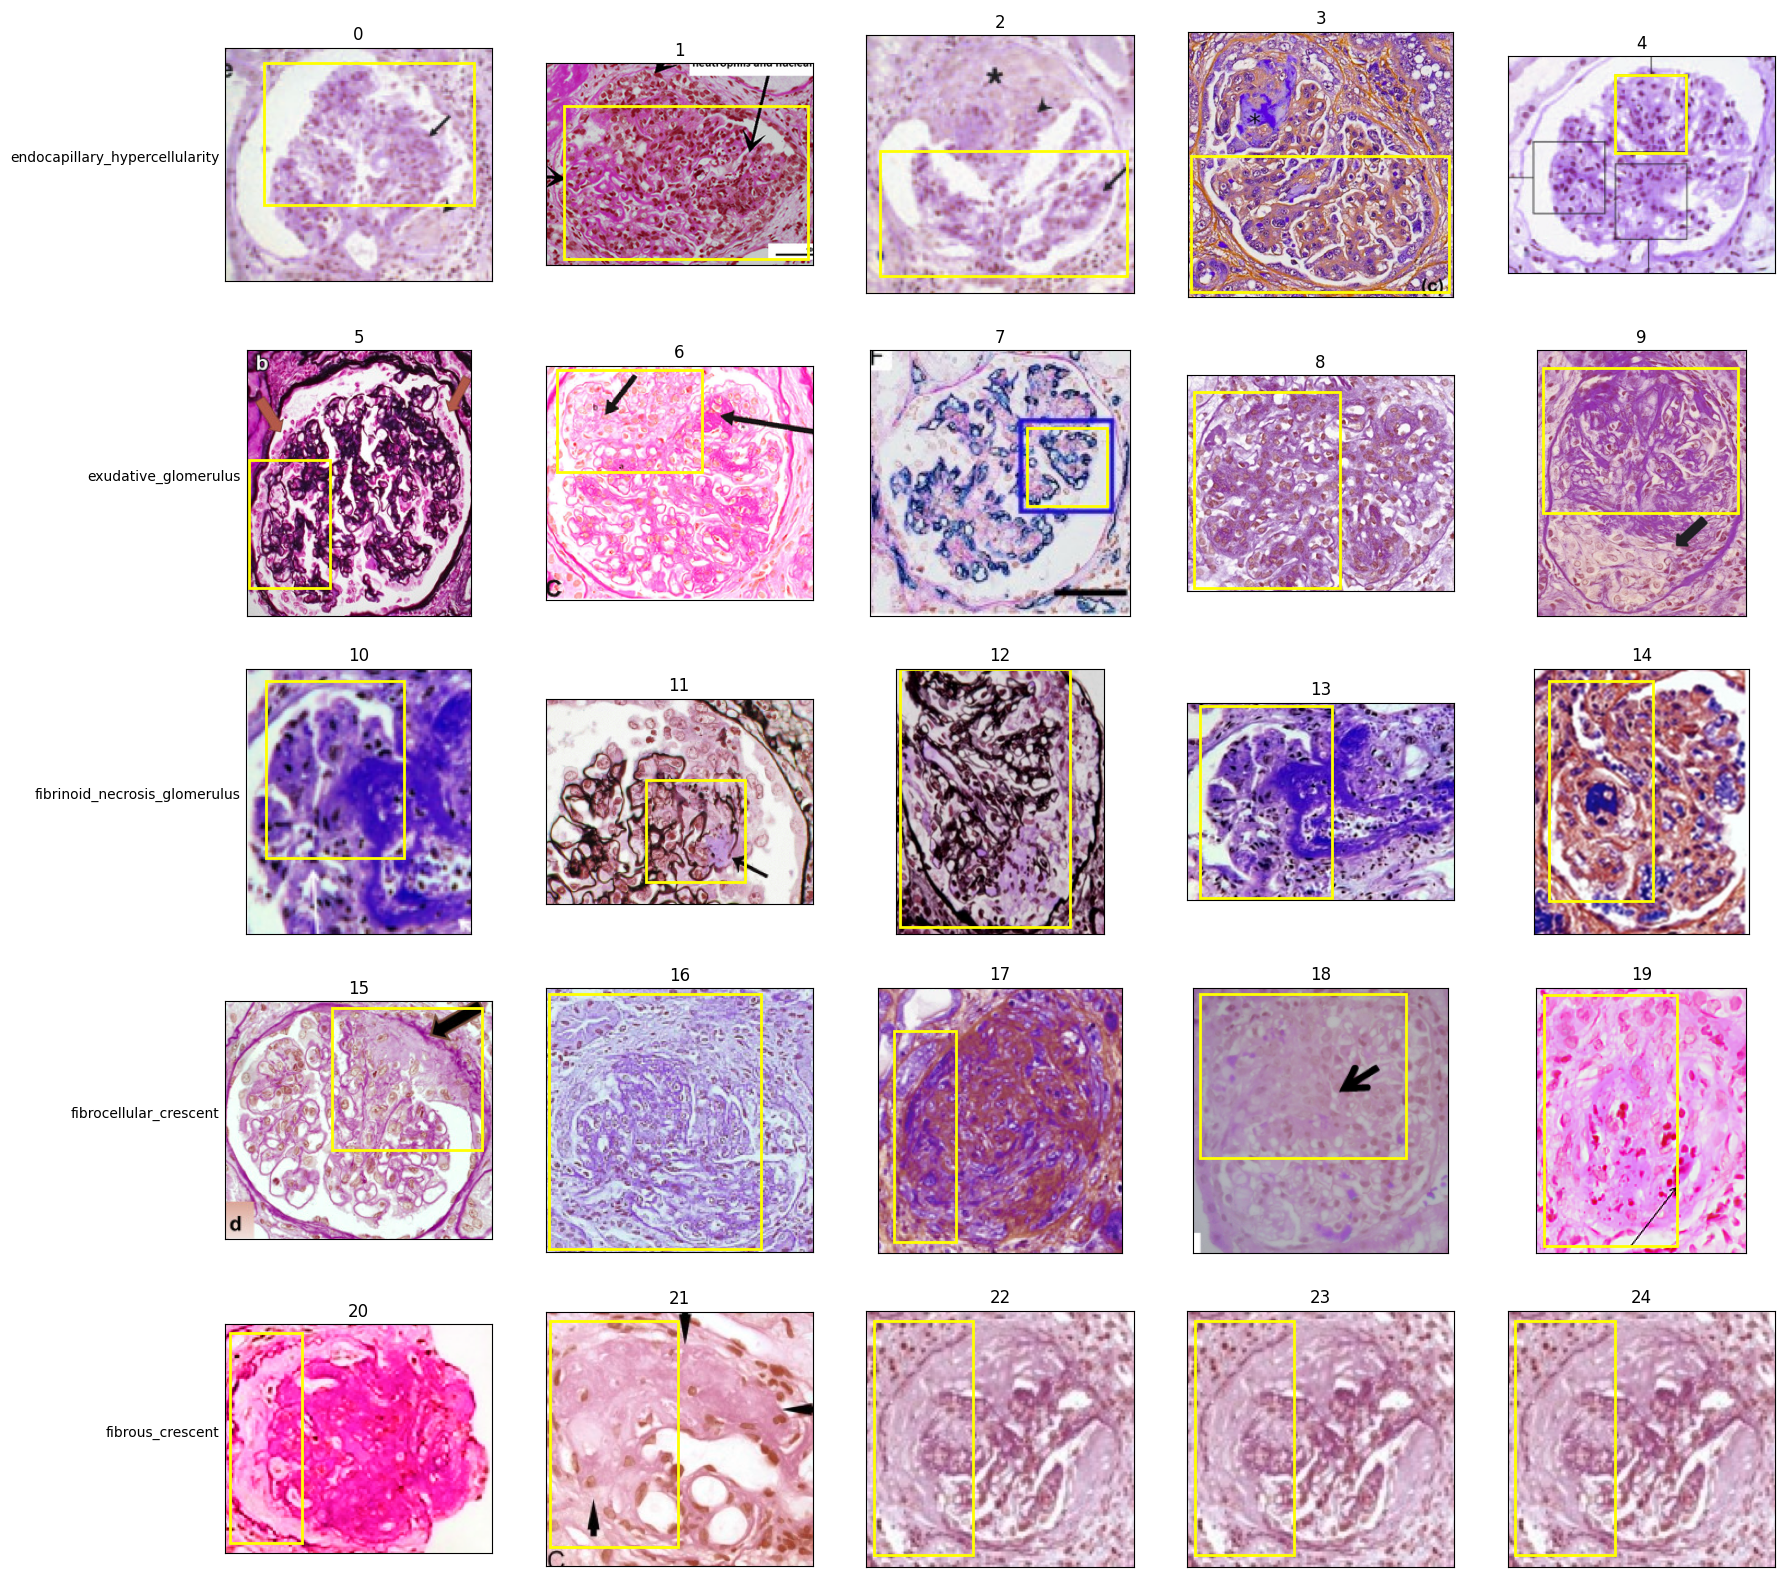

In [97]:
import matplotlib.patches as patches

# visualization of annotation
all_lesion_names = list(new_dict_of_mapping_from_lesion_to_list_of_jsons.keys()) # 42 lesions
start_number = 0
select_number = 5
chosen_lesion_names = all_lesion_names[start_number:start_number + select_number]

# randomly choose 5 images having json for each chosen lesion
list_of_chosen_images = []
list_of_corr_bboxes = []
list_of_img_names = []
for chosen_lesion_name in chosen_lesion_names:
    cur_list_of_jsons = np.array(new_dict_of_mapping_from_lesion_to_list_of_jsons[chosen_lesion_name])
    print(f'- Number of json files of lesion {chosen_lesion_name}: {len(cur_list_of_jsons)}')
    if len(cur_list_of_jsons) < select_number:
        list_of_chosen_indices = list(range(len(cur_list_of_jsons)))
        padded_iters = select_number - len(cur_list_of_jsons)

        last_index = list_of_chosen_indices[-1]
        for padded_iter in range(padded_iters):
            list_of_chosen_indices.append(last_index)

        randomly_chosen_indices = np.array(list_of_chosen_indices)
    else:
        randomly_chosen_indices = np.random.choice(len(cur_list_of_jsons), select_number, replace=False)

    chosen_json_names = cur_list_of_jsons[randomly_chosen_indices]
    corr_img_names = [''.join([chosen_json_name.rsplit('/', 1)[-1].rsplit('.', 1)[0], '.png']) for chosen_json_name in chosen_json_names]

    for rnd_idx, chosen_json_name in enumerate(chosen_json_names):
        json_path = os.path.join(chosen_json_name)
        img_path = os.path.join(GLOM_REFINE_LABO_PATH, ''.join([chosen_lesion_name, '_', corr_img_names[rnd_idx]]))
        with open(json_path) as json_pointer:
            json_content = json.load(json_pointer)
            # print('[**] json_content: ', json_content)

        list_of_img_names.append(corr_img_names[rnd_idx])
        list_of_corr_bboxes.append(json_content)
        list_of_chosen_images.append(cv2.imread(img_path))


figure = plt.figure(figsize=(20, 20))
cols, rows = 5, 5 
print('[**] cols * rows: ', cols * rows)
for i in range(0, cols * rows):
    ax = figure.add_subplot(rows, cols, i+1)
    plt.title(f'{str(i)}')
    # plt.axis("off")

    # plt.tick_params(
    #     axis='x',          # changes apply to the x-axis
    #     which='both',      # both major and minor ticks are affected
    #     bottom=False,      # ticks along the bottom edge are off
    #     top=False,         # ticks along the top edge are off
    #     labelbottom=False) # labels along the bottom edge are of
    ax.set_xticks([])
    ax.set_yticks([])

    plt.imshow(list_of_chosen_images[i], cmap="gray")
    
    real_img_name = map_json_content[list_of_img_names[i].rsplit('.', 1)[0].rsplit('-', 1)[0]]
    print(f'id: {i}, img name: {real_img_name}')
    for bbox_coord in list_of_corr_bboxes[i]:
        x = bbox_coord['left']
        y = bbox_coord['top']
        width = bbox_coord['width']
        height = bbox_coord['height']
        rect = patches.Rectangle((x, y), width, height, linewidth=2, edgecolor='yellow', facecolor='none')
        ax.add_patch(rect)
    if i%cols == 0:
        ax.set_ylabel(chosen_lesion_names[int(i/cols)], rotation="horizontal", horizontalalignment="right")

print(type(chosen_lesion_names))
plt.show()

In [40]:
list(range(9))

[0, 1, 2, 3, 4, 5, 6, 7, 8]